# Weather Data Analysis and Predictive Modelling

## Project Overview

This project explores weather observations from multiple Australian weather stations using statistical analysis and machine learning techniques.

The analysis investigates temperature relationships, rainfall prediction, model validation, and nonlinear patterns in weather data.

## Objectives

- Explore and prepare weather observations from multiple locations.
- Analyse relationships between temperature and other weather variables.
- Develop regression models to estimate maximum temperature.
- Build classification models to predict next-day rainfall.
- Compare model performance using different validation techniques.
- Investigate nonlinear relationships using polynomial regression, splines, and generalized additive models.

## Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Statsmodels

## Project Structure

1. Data Preparation and Exploration
2. Temperature Regression Analysis
3. Rainfall Prediction and Classification
4. Model Validation and Performance Evaluation
5. Polynomial Regression and Spline Analysis
6. Generalized Additive Models
7. Results and Conclusions

## Data Preparation

In [1]:
import re
import sys
from pathlib import Path

import pandas as pd

folder = Path(r"D:\Clients\Formett F&B\Assignments\1\data")
if not folder.exists():
    sys.exit(f"Folder not found: {folder}")
files = sorted(folder.glob("*.csv"))
files = [f for f in files if not f.name.startswith("combined_weather")]
print(f"Found {len(files)} CSV files in {folder.resolve()}")

TITLE_RE = re.compile(r"Daily Weather Observations for (.+?) for ([A-Za-z]+ \d{4})", re.I)


def read_text(path):
    raw = path.read_bytes()
    for enc in ("cp1252", "latin-1"):
        try:
            return raw.decode(enc)
        except UnicodeDecodeError:
            continue
    return raw.decode("utf-8", errors="replace")


def clean_col(c):
    c = re.sub(r"[^\x00-\x7F]", "", str(c))  # drop degree symbol / garbled chars
    return re.sub(r"\s+", " ", c).strip()


frames, problems = [], []

for f in files:
    try:
        lines = read_text(f).splitlines()

        # 1) Location + month from the heading lines
        location, month = None, None
        for line in lines[:15]:
            m = TITLE_RE.search(line)
            if m:
                location, month = m.group(1).strip(), m.group(2).strip()
                break
        if location is None:
            problems.append((f.name, "could not find location in heading"))
            continue

        # 2) Find the real header row (the one containing "Date")
        hdr = next((i for i, l in enumerate(lines) if '"Date"' in l), None)
        if hdr is None:
            problems.append((f.name, "could not find header row"))
            continue

        df = pd.read_csv(f, skiprows=hdr, encoding="cp1252", encoding_errors="replace")
        df.columns = [clean_col(c) for c in df.columns]
        df = df.loc[:, [c for c in df.columns if c and not c.startswith("Unnamed")]]

        # 3) Keep only real data rows
        df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d", errors="coerce")
        df = df.dropna(subset=["Date"])

        df.insert(0, "Location", location)
        df["Month"] = month
        df["Source_File"] = f.name
        frames.append(df)
    except Exception as e:  # keep going if one file is odd
        problems.append((f.name, repr(e)))

combined = pd.concat(frames, ignore_index=True, sort=False)
combined = combined.sort_values(["Location", "Date"]).reset_index(drop=True)

out_csv = folder / "combined_weather.csv"
out_xlsx = folder / "combined_weather.xlsx"
combined.to_csv(out_csv, index=False, encoding="utf-8-sig")
combined.to_excel(out_xlsx, index=False)

print(f"\nCombined {len(frames)} files -> {len(combined)} rows, {combined.shape[1]} columns")
print("Locations found:", combined["Location"].nunique())
print(combined["Location"].value_counts().to_string())
if problems:
    print("\nFiles with problems:")
    for name, why in problems:
        print(f"  {name}: {why}")
print(f"\nSaved: {out_csv}\n       {out_xlsx}")

Found 112 CSV files in D:\Clients\Formett F&B\Assignments\1\data

Combined 111 files -> 3363 rows, 24 columns
Locations found: 8
Location
Adelaide (West Terrace / Ngayirdapira), South Australia    427
Canberra, Australian Capital Territory                     427
Hobart, Tasmania                                           427
Perth, Western Australia                                   427
Sydney, New South Wales                                    427
Darwin, Northern Territory                                 418
Melbourne, Victoria                                        414
Brisbane, Queensland                                       396

Files with problems:
  IDCJDW4019.202508.csv: could not find header row

Saved: D:\Clients\Formett F&B\Assignments\1\data\combined_weather.csv
       D:\Clients\Formett F&B\Assignments\1\data\combined_weather.xlsx


The original monthly weather files were read individually and combined into one dataset. The location and month were extracted from the file headings, and the actual weather-table header was identified before reading the observations. The date column was converted to datetime, invalid dates were removed, and the source filename was retained. This makes it possible to trace observations back to their original files and compare weather records across stations. Missing weather measurements were retained because they may be valid missing observations rather than invalid rows.

## Rainfall Prediction and Classification

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.interpolate import UnivariateSpline
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.model_selection import train_test_split, KFold, cross_val_score, LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score, roc_curve,
                            roc_auc_score, mean_squared_error)
from sklearn.base import clone
from pathlib import Path

DATA_PATH = Path("data/combined_weather.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/combined_weather.csv")
raw = pd.read_csv(DATA_PATH)
weather = raw.copy()
weather["Date"] = pd.to_datetime(weather["Date"], errors="coerce")
rename = {"Minimum temperature (C)":"MinTemp", "Maximum temperature (C)":"MaxTemp",
"Rainfall (mm)":"Rainfall", "Evaporation (mm)":"Evaporation", "Sunshine (hours)":"Sunshine",
"Speed of maximum wind gust (km/h)":"GustSpeed", "9am Temperature (C)":"Temp9am",
"9am relative humidity (%)":"Humidity9am", "9am cloud amount (oktas)":"Cloud9am",
"9am wind direction":"WindDir9am", "9am wind speed (km/h)":"WindSpeed9am",
"9am MSL pressure (hPa)":"Pressure9am", "3pm Temperature (C)":"Temp3pm",
"3pm relative humidity (%)":"Humidity3pm", "3pm cloud amount (oktas)":"Cloud3pm",
"3pm wind direction":"WindDir3pm", "3pm wind speed (km/h)":"WindSpeed3pm",
"3pm MSL pressure (hPa)":"Pressure3pm"}
weather = weather.rename(columns=rename)
weather["Location"] = weather["Location"].astype(str)
numeric = ["MinTemp","MaxTemp","Rainfall","Evaporation","Sunshine","GustSpeed","Temp9am",
"Humidity9am","Cloud9am","WindSpeed9am","Pressure9am","Temp3pm","Humidity3pm","Cloud3pm",
"WindSpeed3pm","Pressure3pm"]
for c in numeric:
    if c in weather:
        weather[c] = pd.to_numeric(weather[c].replace("Calm",0), errors="coerce")
weather = weather.dropna(subset=["Date","Location"]).sort_values(["Location","Date"]).reset_index(drop=True)
weather["RainToday"] = np.where(weather["Rainfall"].isna(), np.nan, (weather["Rainfall"] >= 1).astype(int))
weather["RainTomorrow"] = weather.groupby("Location")["RainToday"].shift(-1)
weather["doy"] = weather["Date"].dt.dayofyear
print(f"Rows: {len(weather):,}; stations: {weather.Location.nunique()}; dates: {weather.Date.min().date()} to {weather.Date.max().date()}")
print(weather.groupby("Location").size())


Rows: 3,363; stations: 8; dates: 2025-07-01 to 2026-08-31
Location
Adelaide (West Terrace / Ngayirdapira), South Australia    427
Brisbane, Queensland                                       396
Canberra, Australian Capital Territory                     427
Darwin, Northern Territory                                 418
Hobart, Tasmania                                           427
Melbourne, Victoria                                        414
Perth, Western Australia                                   427
Sydney, New South Wales                                    427
dtype: int64


### Exploratory Analysis of Temperature Relationships

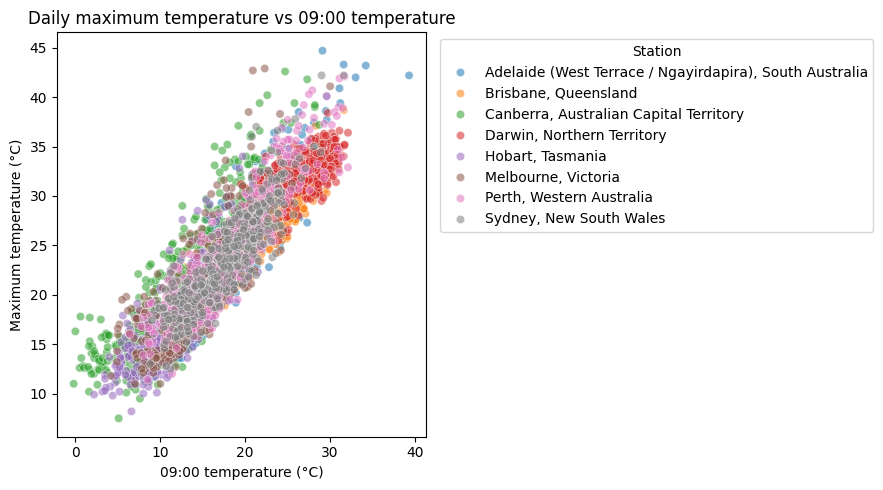

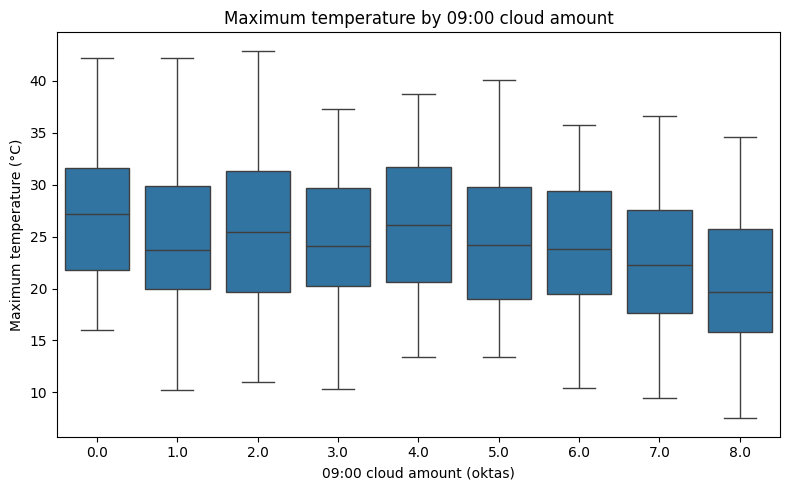

Interpretation: MaxTemp generally rises with Temp9am, though station and weather variation remain. Cloudier mornings tend to be associated with lower or more variable maxima; cloud is discrete and observations are uneven.


In [3]:
fig, ax=plt.subplots(figsize=(9,5))
sns.scatterplot(data=weather, x="Temp9am", y="MaxTemp", hue="Location", alpha=.55, ax=ax)
ax.set(title="Daily maximum temperature vs 09:00 temperature", xlabel="09:00 temperature (°C)", ylabel="Maximum temperature (°C)")
ax.legend(title="Station", bbox_to_anchor=(1.02,1), loc="upper left"); plt.tight_layout(); plt.show()
fig, ax=plt.subplots(figsize=(8,5))
sns.boxplot(data=weather, x="Cloud9am", y="MaxTemp", ax=ax)
ax.set(title="Maximum temperature by 09:00 cloud amount", xlabel="09:00 cloud amount (oktas)", ylabel="Maximum temperature (°C)")
plt.tight_layout(); plt.show()
print("Interpretation: MaxTemp generally rises with Temp9am, though station and weather variation remain. Cloudier mornings tend to be associated with lower or more variable maxima; cloud is discrete and observations are uneven.")

### Simple Linear Regression

                            OLS Regression Results                            
Dep. Variable:                MaxTemp   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.819
Method:                 Least Squares   F-statistic:                 1.517e+04
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:03:27   Log-Likelihood:                -8304.7
No. Observations:                3347   AIC:                         1.661e+04
Df Residuals:                    3345   BIC:                         1.663e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.1461      0.141     50.743      0.0

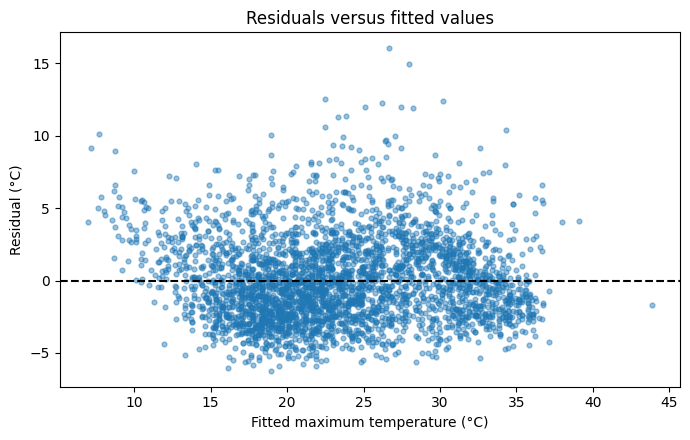

Assess constant spread by checking whether residual dispersion changes across fitted values; a funnel pattern indicates heteroscedasticity.


In [4]:
simple_data=weather.dropna(subset=["MaxTemp","Temp9am"])
simple=smf.ols("MaxTemp ~ Temp9am", data=simple_data).fit()
print(simple.summary())
print(f"Slope={simple.params['Temp9am']:.3f} °C per °C; R²={simple.rsquared:.3f}; residual SE={np.sqrt(simple.mse_resid):.3f} °C.")
fig, ax=plt.subplots(figsize=(7,4.5))
ax.scatter(simple.fittedvalues, simple.resid, s=12, alpha=.45)
ax.axhline(0, color="black", linestyle="--")
ax.set(title="Residuals versus fitted values", xlabel="Fitted maximum temperature (°C)", ylabel="Residual (°C)")
plt.tight_layout(); plt.show()
print("Assess constant spread by checking whether residual dispersion changes across fitted values; a funnel pattern indicates heteroscedasticity.")

The fitted model is:
\[
\widehat{MaxTemp}=7.1463+0.9342(Temp9am)
\]

- Slope: 0.9342
- R²: 0.819
- Residual standard error: 2.886 °C
- Observations: 3,378
For each 1°C increase in 9am temperature, predicted maximum temperature increases by approximately 0.934°C. The model explains 81.9% of the observed variation in maximum temperature.

The residual standard error of 2.886°C indicates that predictions still have substantial day-to-day variation. The residual plot should be checked for changing spread; a funnel pattern would indicate heteroscedasticity.

### Multiple Linear Regression

In [5]:
new_day = pd.DataFrame({"Temp9am":[14], "Humidity9am":[70], "Pressure9am":[1018], "MinTemp":[9], "Location":[weather.Location.mode()[0]]})

In [6]:
f_d="MaxTemp ~ Temp9am + Humidity9am + Pressure9am + MinTemp + C(Location)"
md=weather.dropna(subset=["MaxTemp","Temp9am","Humidity9am","Pressure9am","MinTemp","Location"]).copy()
multiple=smf.ols(f_d,data=md).fit()
print(multiple.summary())
print("Simple vs multiple Temp9am slope:",simple.params.get("Temp9am"),multiple.params.get("Temp9am"))
print("Location coefficients are offsets relative to the reference station; they adjust for station climate/measurement differences.")
pred=multiple.get_prediction(new_day).summary_frame(alpha=.05)
display(pred)

                            OLS Regression Results                            
Dep. Variable:                MaxTemp   R-squared:                       0.853
Model:                            OLS   Adj. R-squared:                  0.853
Method:                 Least Squares   F-statistic:                     1761.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:03:27   Log-Likelihood:                -7955.5
No. Observations:                3346   AIC:                         1.593e+04
Df Residuals:                    3334   BIC:                         1.601e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,19.579714,0.133625,19.317718,19.84171,14.44998,24.709448


The Temp9am coefficient increases from 0.9342 in the simple model to 1.2103 in the multiple model. This means its estimated effect changes after accounting for the other predictors.

Holding other variables constant, a 1°C increase in 9am temperature is associated with a predicted increase of 1.2103°C in maximum temperature. The negative humidity coefficient indicates a small decrease in predicted maximum temperature for each percentage-point increase in morning humidity, conditional on the other predictors.

The station coefficients are offsets relative to the reference station. The model R² increases from 0.819 to 0.852 after adding the additional predictors.

### Investigating Data Leakage

In [7]:
leak=smf.ols(f_d+" + Temp3pm + Sunshine",data=weather.dropna(subset=["MaxTemp","Temp9am","Humidity9am","Pressure9am","MinTemp","Location","Temp3pm","Sunshine"])).fit()
print("R² without leakage:",multiple.rsquared,"with 15:00/sunshine:",leak.rsquared)
print("Temp3pm and Sunshine are observed after the morning forecast time and are downstream of the day's weather; using them leaks future information.")

R² without leakage: 0.8531548120161079 with 15:00/sunshine: 0.9718845911387303
Temp3pm and Sunshine are observed after the morning forecast time and are downstream of the day's weather; using them leaks future information.


### Location-Based Regression Interactions

In [8]:
import statsmodels.formula.api as smf

mf = weather.dropna(
    subset=["MaxTemp", "Temp9am", "Location"]
).copy()

mf["Location"] = mf["Location"].astype("category")

print("Number of locations:", mf["Location"].nunique())

parallel = smf.ols(
    "MaxTemp ~ Temp9am + C(Location)",
    data=mf
).fit()

interaction = smf.ols(
    "MaxTemp ~ Temp9am * C(Location)",
    data=mf
).fit()

print("\nNested-model F-test:")
print(interaction.compare_f_test(parallel))

print("\nInteraction coefficients:")
print(interaction.params)

Number of locations: 8

Nested-model F-test:
(43.0479123884772, 1.57095709082979e-58, 7.0)

Interaction coefficients:
Intercept                                                         2.413969
C(Location)[T.Brisbane, Queensland]                               7.950454
C(Location)[T.Canberra, Australian Capital Territory]             5.848282
C(Location)[T.Darwin, Northern Territory]                        19.834050
C(Location)[T.Hobart, Tasmania]                                   4.208764
C(Location)[T.Melbourne, Victoria]                                2.846213
C(Location)[T.Perth, Western Australia]                           3.366015
C(Location)[T.Sydney, New South Wales]                            3.508014
Temp9am                                                           1.186190
Temp9am:C(Location)[T.Brisbane, Queensland]                      -0.446570
Temp9am:C(Location)[T.Canberra, Australian Capital Territory]    -0.172165
Temp9am:C(Location)[T.Darwin, Northern Territory]        

In [9]:
print("Parallel model formula:", parallel.model.formula)
print("Interaction model formula:", interaction.model.formula)

print("\nParallel model parameters:")
print(parallel.params)

print("\nInteraction model parameters:")
print(interaction.params)

print("\nParallel model:")
print("Parameters:", len(parallel.params))
print("Residual df:", parallel.df_resid)
print("Residual SSR:", parallel.ssr)
print("R-squared:", parallel.rsquared)

print("\nInteraction model:")
print("Parameters:", len(interaction.params))
print("Residual df:", interaction.df_resid)
print("Residual SSR:", interaction.ssr)
print("R-squared:", interaction.rsquared)

print("\nInteraction design matrix:")
print(interaction.model.exog_names)

Parallel model formula: MaxTemp ~ Temp9am + C(Location)
Interaction model formula: MaxTemp ~ Temp9am * C(Location)

Parallel model parameters:
Intercept                                                5.833262
C(Location)[T.Brisbane, Queensland]                     -0.760016
C(Location)[T.Canberra, Australian Capital Territory]    2.865928
C(Location)[T.Darwin, Northern Territory]                0.381469
C(Location)[T.Hobart, Tasmania]                          0.119078
C(Location)[T.Melbourne, Victoria]                       0.340328
C(Location)[T.Perth, Western Australia]                  0.852795
C(Location)[T.Sydney, New South Wales]                   0.448086
Temp9am                                                  0.978760
dtype: float64

Interaction model parameters:
Intercept                                                         2.413969
C(Location)[T.Brisbane, Queensland]                               7.950454
C(Location)[T.Canberra, Australian Capital Territory]             5

The reference station has slope 1.1862. The station-specific slopes are obtained by adding each interaction coefficient to this reference slope.

For example, Brisbane's slope is approximately 0.7427, while Darwin's is approximately 0.3807. This shows that the morning-to-maximum temperature relationship varies across cities.

## Rainfall Prediction and Classification

In [ ]:
rain <- subset(weather, !is.na(RainTomorrow))

### Baseline Rainfall Classification

In [11]:
rain=weather.dropna(subset=["RainTomorrow"]).copy()
y=rain["RainTomorrow"].astype(int)
base=np.zeros(len(y), dtype=int)
print(f"RainTomorrow rainy fraction: {y.mean():.3f} ({y.sum()} of {len(y)} days)")
print("Always-no-rain confusion matrix [rows=true 0/1, cols=pred 0/1]:")
print(confusion_matrix(y,base))
print(f"Accuracy={accuracy_score(y,base):.3f}; this equals the non-rain fraction.")

RainTomorrow rainy fraction: 0.248 (829 of 3341 days)
Always-no-rain confusion matrix [rows=true 0/1, cols=pred 0/1]:
[[2512    0]
 [ 829    0]]
Accuracy=0.752; this equals the non-rain fraction.


### Logistic Regression with Humidity

                           Logit Regression Results                           
Dep. Variable:           RainTomorrow   No. Observations:                 3336
Model:                          Logit   Df Residuals:                     3334
Method:                           MLE   Df Model:                            1
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.2037
Time:                        12:08:36   Log-Likelihood:                -1489.3
converged:                       True   LL-Null:                       -1870.4
Covariance Type:            nonrobust   LLR p-value:                9.005e-168
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -5.4785      0.204    -26.911      0.000      -5.877      -5.079
Humidity3pm     0.0755      0.003     23.102      0.000       0.069       0.082
Odds ratio per +10 humidity points=2.127; equal-

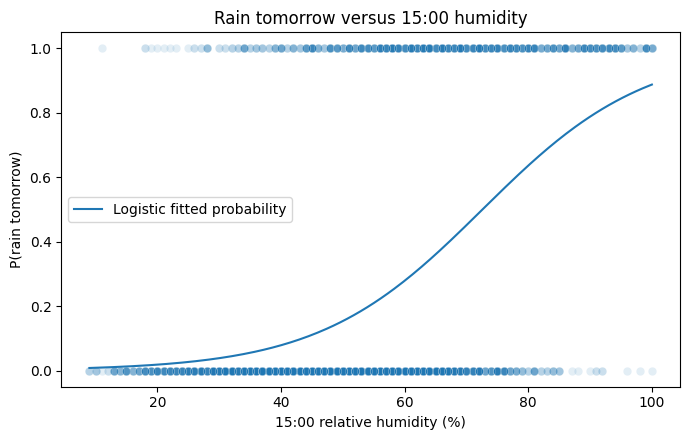

In [12]:
r1=rain.dropna(subset=["Humidity3pm","RainTomorrow"]).copy()
y1=r1.RainTomorrow.astype(int)
logit1=smf.logit("RainTomorrow ~ Humidity3pm",data=r1).fit(disp=False)
print(logit1.summary())
or10=np.exp(10*logit1.params["Humidity3pm"])
cut=-logit1.params["Intercept"]/logit1.params["Humidity3pm"]
print(f"Odds ratio per +10 humidity points={or10:.3f}; equal-probability humidity={cut:.2f}%")
xx=np.linspace(r1.Humidity3pm.min(),r1.Humidity3pm.max(),250)
plt.figure(figsize=(7,4.5)); sns.scatterplot(data=r1,x="Humidity3pm",y="RainTomorrow",alpha=.12)
plt.plot(xx,logit1.predict(pd.DataFrame({"Humidity3pm":xx})),label="Logistic fitted probability")
plt.title("Rain tomorrow versus 15:00 humidity"); plt.xlabel("15:00 relative humidity (%)"); plt.ylabel("P(rain tomorrow)"); plt.legend(); plt.tight_layout(); plt.show()

### Multivariable Logistic Regression

In [13]:
features=["Humidity3pm","Pressure3pm","GustSpeed","RainToday","Location"]
r2=rain.dropna(subset=features+["RainTomorrow"]).copy()
r2["RainTomorrow"]=r2.RainTomorrow.astype(int); r2["RainToday"]=r2.RainToday.astype(int)
formula="RainTomorrow ~ Humidity3pm + Pressure3pm + GustSpeed + RainToday + C(Location)"
logit=smf.logit(formula,data=r2).fit(disp=False)
print(logit.summary())
print("Odds ratios (exp coefficients):"); print(np.exp(logit.params))
p=logit.predict(r2); pred=(p>=.5).astype(int); cm=confusion_matrix(r2.RainTomorrow,pred)
print("Confusion matrix:",cm); print(f"Accuracy={accuracy_score(r2.RainTomorrow,pred):.3f}, sensitivity={recall_score(r2.RainTomorrow,pred):.3f}, specificity={cm[0,0]/cm[0].sum():.3f}")
print("RainToday coefficient/p-value:",logit.params.get("RainToday"),logit.pvalues.get("RainToday"))

                           Logit Regression Results                           
Dep. Variable:           RainTomorrow   No. Observations:                 3264
Model:                          Logit   Df Residuals:                     3252
Method:                           MLE   Df Model:                           11
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.2907
Time:                        12:08:38   Log-Likelihood:                -1292.5
converged:                       True   LL-Null:                       -1822.2
Covariance Type:            nonrobust   LLR p-value:                3.165e-220
                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                39.5736      7.459      5.305      0.000      24.954      54.193
C(

### Linear Discriminant Analysis (LDA)

In [14]:
X=r2[["Humidity3pm","Pressure3pm","GustSpeed"]]; y=r2.RainTomorrow
lda=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LinearDiscriminantAnalysis()).fit(X,y)
pl=lda.predict(X); cm=confusion_matrix(y,pl)
print("LDA confusion matrix:",cm); print(f"Accuracy={accuracy_score(y,pl):.3f}")
print("LDA assumes each class has a multivariate normal predictor distribution and a common covariance matrix.")

LDA confusion matrix: [[2306  154]
 [ 430  374]]
Accuracy=0.821
LDA assumes each class has a multivariate normal predictor distribution and a common covariance matrix.


### Quadratic Discriminant Analysis (QDA)

In [15]:
qda=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),QuadraticDiscriminantAnalysis()).fit(X,y)
pq=qda.predict(X); cmq=confusion_matrix(y,pq)
print("QDA confusion matrix:",cmq); print(f"Accuracy={accuracy_score(y,pq):.3f}")
print("QDA permits class-specific covariance matrices (unlike LDA); whether it helps is determined by the observed accuracy and later CV results.")

QDA confusion matrix: [[2305  155]
 [ 428  376]]
Accuracy=0.821
QDA permits class-specific covariance matrices (unlike LDA); whether it helps is determined by the observed accuracy and later CV results.


### Classification Threshold Analysis

In [16]:
p30=logit.predict(r2); y=r2.RainTomorrow.astype(int)
for threshold in [.5,.3]:
    pr=(p30>=threshold).astype(int); cm=confusion_matrix(y,pr)
    print(f"threshold={threshold}: CM={cm.tolist()}, sensitivity={recall_score(y,pr):.3f}, specificity={cm[0,0]/cm[0].sum():.3f}, accuracy={accuracy_score(y,pr):.3f}")
print("For a commuter who strongly avoids getting soaked, 0.3 is more precautionary: sensitivity rises and specificity usually falls. Accuracy ignores the asymmetric cost of missed rain.")

threshold=0.5: CM=[[2318, 142], [421, 383]], sensitivity=0.476, specificity=0.942, accuracy=0.828
threshold=0.3: CM=[[2056, 404], [246, 558]], sensitivity=0.694, specificity=0.836, accuracy=0.801
For a commuter who strongly avoids getting soaked, 0.3 is more precautionary: sensitivity rises and specificity usually falls. Accuracy ignores the asymmetric cost of missed rain.


### ROC Curve and AUC Evaluation

Logistic AUC 0.839
LDA AUC 0.825
QDA AUC 0.818


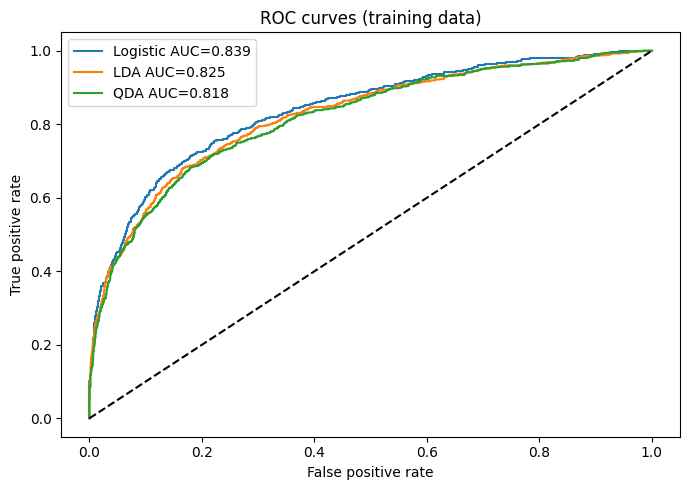

AUC ranks discrimination across all thresholds; threshold accuracy depends on one cutoff and class balance, so rankings can differ.


In [17]:
models={"Logistic":logit,"LDA":lda,"QDA":qda}
plt.figure(figsize=(7,5))
for name,model in models.items():
    if name=="Logistic": scores=model.predict(r2)
    else: scores=model.predict_proba(X)[:,1]
    fpr,tpr,_=roc_curve(y,scores); auc=roc_auc_score(y,scores)
    plt.plot(fpr,tpr,label=f"{name} AUC={auc:.3f}")
    print(name,"AUC",round(auc,3))
plt.plot([0,1],[0,1],"k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (training data)"); plt.legend(); plt.tight_layout(); plt.show()
print("AUC ranks discrimination across all thresholds; threshold accuracy depends on one cutoff and class balance, so rankings can differ.")

## Model Validation and Performance Evaluation

### Random vs Temporal Validation

In [18]:
r3=rain.dropna(subset=["Humidity3pm","Pressure3pm","GustSpeed","RainToday","RainTomorrow"]).copy()
r3["RainTomorrow"]=r3.RainTomorrow.astype(int); r3["RainToday"]=r3.RainToday.astype(int)
X3=r3[["Humidity3pm","Pressure3pm","GustSpeed","RainToday"]]; y3=r3.RainTomorrow
Xtr,Xte,ytr,yte=train_test_split(X3,y3,test_size=.30,random_state=42,stratify=y3)
pipe=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LogisticRegression(max_iter=2000))
pipe.fit(Xtr,ytr); random_err=1-accuracy_score(yte,pipe.predict(Xte))
r3=r3.sort_values("Date"); cutoff=r3.Date.min()+pd.DateOffset(months=10)
tr=r3[r3.Date<cutoff]; te=r3[r3.Date>=cutoff]
pt=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LogisticRegression(max_iter=2000))
pt.fit(tr[["Humidity3pm","Pressure3pm","GustSpeed","RainToday"]],tr.RainTomorrow.astype(int))
temporal_err=1-accuracy_score(te.RainTomorrow.astype(int),pt.predict(te[["Humidity3pm","Pressure3pm","GustSpeed","RainToday"]]))
print(f"Random 70/30 test error={random_err:.3f}; earliest 10 months -> latest 4 months error={temporal_err:.3f}; temporal cutoff={cutoff.date()}")
print("Random splitting mixes neighboring days and seasonal regimes across train/test, making the test set easier. The temporal split better mimics forecasting future days.")

Random 70/30 test error=0.202; earliest 10 months -> latest 4 months error=0.194; temporal cutoff=2026-05-01
Random splitting mixes neighboring days and seasonal regimes across train/test, making the test set easier. The temporal split better mimics forecasting future days.


### Polynomial Regression and Degree Selection

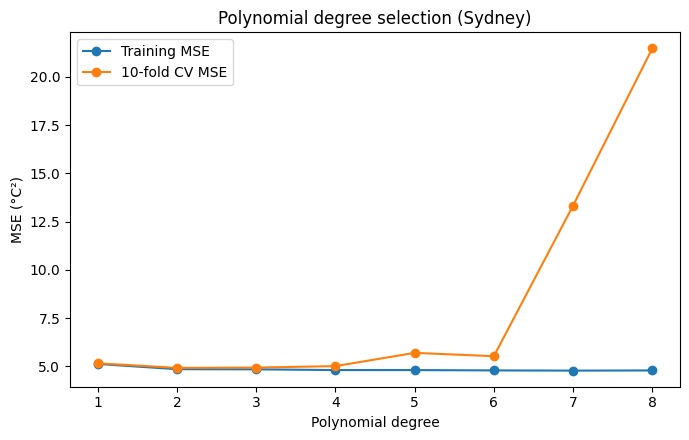

CV errors by degree: {1: 5.1612, 2: 4.9233, 3: 4.9397, 4: 5.0141, 5: 5.7008, 6: 5.5283, 7: 13.3266, 8: 21.469}
Selected degree: 2
The training error generally decreases as degree increases, but CV estimates future prediction error.
I select the degree with the lowest CV error; if nearby values are similar, the lower degree is easier to justify.


In [19]:
# I use chronological ordering for the displayed data, then shuffled folds for CV.
syd = weather[weather.Location.str.contains("Sydney", case=False)].dropna(
    subset=["MaxTemp", "Temp9am"]
).copy()
degrees = range(1, 9)
trainm, cv10 = [], []
xx = syd[["Temp9am"]]
yy = syd["MaxTemp"]
cv = KFold(10, shuffle=True, random_state=1)

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        LinearRegression()
    )
    model.fit(xx, yy)
    trainm.append(mean_squared_error(yy, model.predict(xx)))
    cv10.append(-cross_val_score(
        model, xx, yy, cv=cv, scoring="neg_mean_squared_error"
    ).mean())

plt.figure(figsize=(7, 4.5))
plt.plot(list(degrees), trainm, "o-", label="Training MSE")
plt.plot(list(degrees), cv10, "o-", label="10-fold CV MSE")
plt.xlabel("Polynomial degree")
plt.ylabel("MSE (°C²)")
plt.title("Polynomial degree selection (Sydney)")
plt.legend()
plt.tight_layout()
plt.show()

best_degree = list(degrees)[int(np.argmin(cv10))]
print("CV errors by degree:", dict(zip(degrees, np.round(cv10, 4))))
print("Selected degree:", best_degree)
print("The training error generally decreases as degree increases, but CV estimates future prediction error.")
print("I select the degree with the lowest CV error; if nearby values are similar, the lower degree is easier to justify.")

### Cross-Validation Model Comparison

In [20]:
common=r2.dropna(subset=["Humidity3pm","Pressure3pm","GustSpeed","RainTomorrow"]).copy()
XX=common[["Humidity3pm","Pressure3pm","GustSpeed"]]; yy=common.RainTomorrow.astype(int)
cv=KFold(10,shuffle=True,random_state=42)
estimators={"Logistic":make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LogisticRegression(max_iter=2000)),"LDA":make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LinearDiscriminantAnalysis()),"QDA":make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),QuadraticDiscriminantAnalysis())}
rows=[]
for name,est in estimators.items():
    errs=1-cross_val_score(est,XX,yy,cv=cv,scoring="accuracy")
    rows.append({"Model":name,"10-fold CV error":errs.mean(),"Fold SD":errs.std()})
cv_table=pd.DataFrame(rows); display(cv_table)
print("Use the lowest CV error, but interpret small differences relative to fold-to-fold variability.")

,Model,10-fold CV error,Fold SD
0,Logistic,0.176473,0.018767
1,LDA,0.179544,0.018479
2,QDA,0.179544,0.020329


Use the lowest CV error, but interpret small differences relative to fold-to-fold variability.


### Cross-Validation Stability

In [21]:
seed_errors=[]
for seed in [1,2,3,4,5]:
    cv=KFold(10,shuffle=True,random_state=seed)
    e=1-cross_val_score(estimators["Logistic"],XX,yy,cv=cv,scoring="accuracy")
    seed_errors.append(e.mean())
print("Seeds 1..5 CV errors:",np.round(seed_errors,4))
print(f"Mean={np.mean(seed_errors):.4f}; range={np.ptp(seed_errors):.4f}; SD={np.std(seed_errors,ddof=1):.4f}")
print("CV estimates vary with fold assignment; report precision no finer than the observed variability supports.")

Seeds 1..5 CV errors: [0.1768 0.1765 0.1762 0.1759 0.1771]
Mean=0.1765; range=0.0012; SD=0.0005
CV estimates vary with fold assignment; report precision no finer than the observed variability supports.


### Leave-One-Station-Out Validation

In [22]:
station_errors=[]
for station in common.Location.unique():
    train=common[common.Location!=station]; test=common[common.Location==station]
    model=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LogisticRegression(max_iter=2000))
    model.fit(train[["Humidity3pm","Pressure3pm","GustSpeed"]],train.RainTomorrow.astype(int))
    err=1-accuracy_score(test.RainTomorrow.astype(int),model.predict(test[["Humidity3pm","Pressure3pm","GustSpeed"]]))
    station_errors.append((station,err,len(test)))
station_table=pd.DataFrame(station_errors,columns=["Station","Error rate","Test n"]).sort_values("Error rate",ascending=False); display(station_table)
print("The highest error station is hardest in this leave-one-station-out test. This evaluates transfer to a city unseen during training.")

,Station,Error rate,Test n
7,"Sydney, New South Wales",0.221429,420
5,"Melbourne, Victoria",0.204938,405
1,"Brisbane, Queensland",0.195876,388
4,"Hobart, Tasmania",0.195181,415
0,"Adelaide (West Terrace / Ngayirdapira), South ...",0.184397,423
6,"Perth, Western Australia",0.168646,421
2,"Canberra, Australian Capital Territory",0.137592,407
3,"Darwin, Northern Territory",0.124675,385


The highest error station is hardest in this leave-one-station-out test. This evaluates transfer to a city unseen during training.


------------------------------------------------------------------------

## Nonlinear Modelling and Generalized Additive Models


### Seasonal Trends Using Polynomial and Spline Models

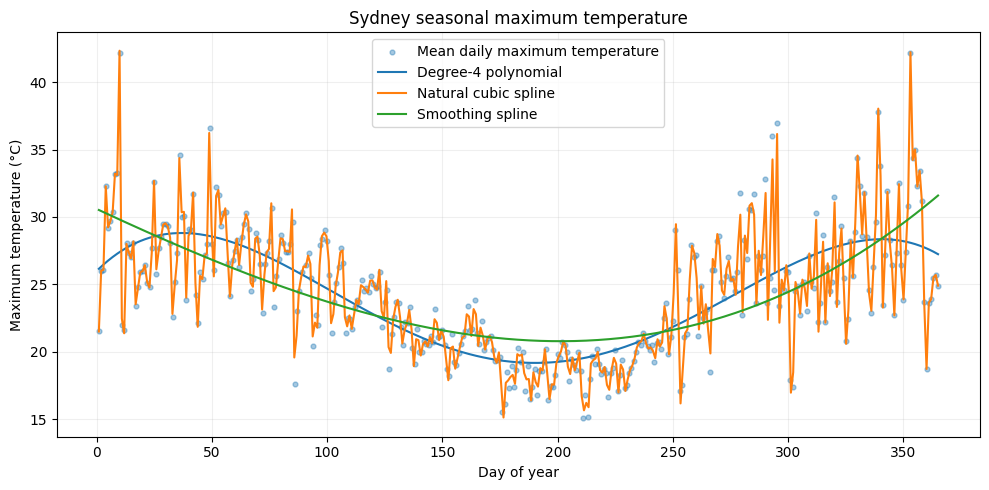

The polynomial is global, so a change near one end can affect the curve elsewhere.
The natural spline follows the seasonal averages locally and has zero second derivative at its boundaries.
The smoothing spline trades fit for smoothness, so it suppresses day-to-day noise.
The curves can disagree most near the boundaries, where there are fewer neighboring days to constrain them.
I would trust the smoothing spline for the broad seasonal pattern, while treating endpoint behavior cautiously.


In [24]:
# First average across years so each day-of-year has one temperature value.
from scipy.interpolate import CubicSpline, UnivariateSpline
syd = weather[weather["Location"].str.contains("Sydney", case=False)].dropna(
    subset=["MaxTemp", "doy"]
).copy()
seasonal = syd.groupby("doy", as_index=False)["MaxTemp"].mean().sort_values("doy")
x = seasonal["doy"].to_numpy()
y = seasonal["MaxTemp"].to_numpy()
grid = np.linspace(x.min(), x.max(), 366)

# Degree-four polynomial
p4 = np.poly1d(np.polyfit(x, y, 4))
poly_curve = p4(grid)

# Natural cubic spline through observed seasonal averages
natural_spline = CubicSpline(x, y, bc_type="natural")
natural_curve = natural_spline(grid)

# Smoothing spline: s controls how much short-term variation is smoothed.
smooth = UnivariateSpline(x, y, k=3, s=len(x) * np.var(y) * 0.7)
smooth_curve = smooth(grid)

plt.figure(figsize=(10, 5))
plt.scatter(x, y, s=12, alpha=0.4, label="Mean daily maximum temperature")
plt.plot(grid, poly_curve, label="Degree-4 polynomial")
plt.plot(grid, natural_curve, label="Natural cubic spline")
plt.plot(grid, smooth_curve, label="Smoothing spline")
plt.xlabel("Day of year")
plt.ylabel("Maximum temperature (°C)")
plt.title("Sydney seasonal maximum temperature")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("The polynomial is global, so a change near one end can affect the curve elsewhere.")
print("The natural spline follows the seasonal averages locally and has zero second derivative at its boundaries.")
print("The smoothing spline trades fit for smoothness, so it suppresses day-to-day noise.")
print("The curves can disagree most near the boundaries, where there are fewer neighboring days to constrain them.")
print("I would trust the smoothing spline for the broad seasonal pattern, while treating endpoint behavior cautiously.")

### Nonlinear Logistic Regression

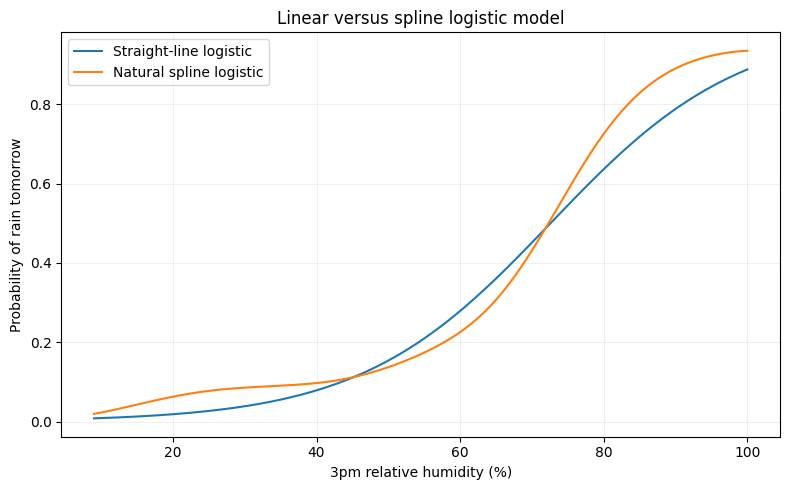

Linear logistic CV error: 0.1856
Natural spline CV error: 0.1868
Difference: -0.0012


In [25]:
r4 = rain.dropna(
    subset=["Humidity3pm", "RainTomorrow"]
).copy()

r4["RainTomorrow"] = r4["RainTomorrow"].astype(int)

X = r4[["Humidity3pm"]]
y = r4["RainTomorrow"]

straight = smf.logit(
    "RainTomorrow ~ Humidity3pm",
    data=r4
).fit(disp=False)

spline_model = make_pipeline(
    SplineTransformer(
        n_knots=5,
        degree=3,
        knots="quantile",
        include_bias=False,
        extrapolation="linear"
    ),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

spline_model.fit(X, y)

grid = np.linspace(
    X["Humidity3pm"].min(),
    X["Humidity3pm"].max(),
    250
)

grid_df = pd.DataFrame({
    "Humidity3pm": grid
})

linear_prob = straight.predict(grid_df)

spline_prob = spline_model.predict_proba(
    grid_df
)[:, 1]

plt.figure(figsize=(8, 5))

plt.plot(
    grid,
    linear_prob,
    label="Straight-line logistic"
)

plt.plot(
    grid,
    spline_prob,
    label="Natural spline logistic"
)

plt.xlabel("3pm relative humidity (%)")
plt.ylabel("Probability of rain tomorrow")
plt.title("Linear versus spline logistic model")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

linear_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

spline_cv_model = make_pipeline(
    SplineTransformer(
        n_knots=5,
        degree=3,
        knots="quantile",
        include_bias=False,
        extrapolation="linear"
    ),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

linear_error = 1 - cross_val_score(
    linear_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
).mean()

spline_error = 1 - cross_val_score(
    spline_cv_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
).mean()

print(f"Linear logistic CV error: {linear_error:.4f}")
print(f"Natural spline CV error: {spline_error:.4f}")
print(f"Difference: {linear_error - spline_error:.4f}")

### Generalized Additive Modelling

                            OLS Regression Results                            
Dep. Variable:                MaxTemp   R-squared:                       0.867
Model:                            OLS   Adj. R-squared:                  0.866
Method:                 Least Squares   F-statistic:                     654.7
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:09:45   Log-Likelihood:                -7791.4
No. Observations:                3347   AIC:                         1.565e+04
Df Residuals:                    3313   BIC:                         1.586e+04
Df Model:                          33                                         
Covariance Type:            nonrobust                                         
                                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

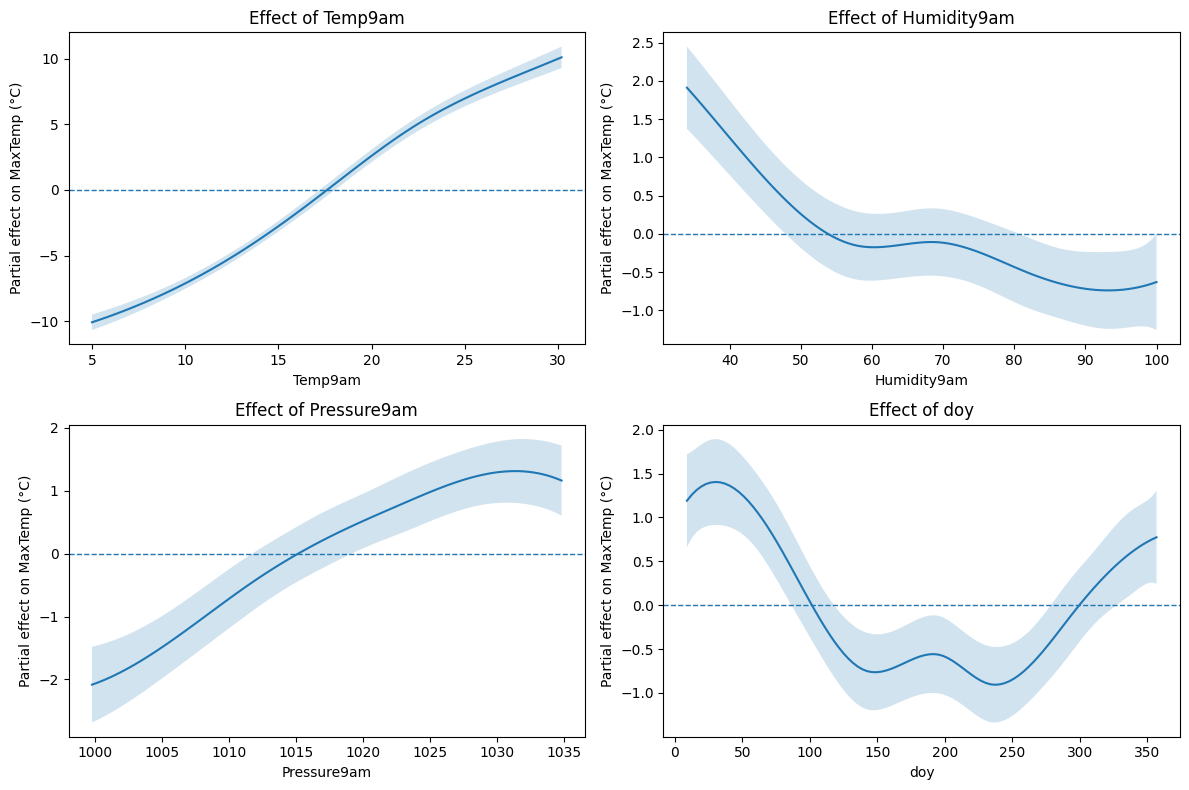

In [26]:
gamdata = weather.dropna(
    subset=[
        "MaxTemp",
        "Temp9am",
        "Humidity9am",
        "Pressure9am",
        "doy",
        "Location"
    ]
).copy()

gam_formula = (
    "MaxTemp ~ C(Location)"
    " + bs(Temp9am, df=6, degree=3)"
    " + bs(Humidity9am, df=6, degree=3)"
    " + bs(Pressure9am, df=6, degree=3)"
    " + bs(doy, df=8, degree=3)"
)

gam = smf.ols(
    gam_formula,
    data=gamdata
).fit()

print(gam.summary())

smooth_vars = [
    "Temp9am",
    "Humidity9am",
    "Pressure9am",
    "doy"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8)
)

for var, ax in zip(smooth_vars, axes.flat):

    values = np.linspace(
        gamdata[var].quantile(0.02),
        gamdata[var].quantile(0.98),
        100
    )

    newdata = pd.DataFrame({
        "Location": [gamdata["Location"].mode()[0]] * len(values),
        "Temp9am": [gamdata["Temp9am"].median()] * len(values),
        "Humidity9am": [gamdata["Humidity9am"].median()] * len(values),
        "Pressure9am": [gamdata["Pressure9am"].median()] * len(values),
        "doy": [gamdata["doy"].median()] * len(values)
    })

    newdata[var] = values

    pred = gam.get_prediction(newdata).summary_frame()

    effect = pred["mean"] - pred["mean"].mean()

    lower = pred["mean_ci_lower"] - pred["mean"].mean()
    upper = pred["mean_ci_upper"] - pred["mean"].mean()

    ax.plot(
        values,
        effect,
        label="Smooth effect"
    )

    ax.fill_between(
        values,
        lower,
        upper,
        alpha=0.2,
        label="95% CI"
    )

    ax.axhline(0, linestyle="--", linewidth=1)

    ax.set_xlabel(var)
    ax.set_ylabel("Partial effect on MaxTemp (°C)")
    ax.set_title(f"Effect of {var}")

plt.tight_layout()
plt.show()

### Temporal Performance Comparison

In [27]:
d = weather.dropna(
    subset=[
        "MaxTemp",
        "Temp9am",
        "Humidity9am",
        "Pressure9am",
        "MinTemp",
        "Location",
        "doy"
    ]
).copy()

d = d.sort_values("Date")

cutoff = d["Date"].min() + pd.DateOffset(months=10)

train = d[d["Date"] < cutoff].copy()
test = d[d["Date"] >= cutoff].copy()

print("Training period:",
      train.Date.min(), "to", train.Date.max())

print("Testing period:",
      test.Date.min(), "to", test.Date.max())

linear_formula = (
    "MaxTemp ~ Temp9am + Humidity9am"
    " + Pressure9am + MinTemp + C(Location)"
)

linear_model = smf.ols(
    linear_formula,
    data=train
).fit()

linear_pred = linear_model.predict(test)

linear_mse = mean_squared_error(
    test["MaxTemp"],
    linear_pred
)

temp_min = d["Temp9am"].min()
temp_max = d["Temp9am"].max()

humidity_min = d["Humidity9am"].min()
humidity_max = d["Humidity9am"].max()

pressure_min = d["Pressure9am"].min()
pressure_max = d["Pressure9am"].max()

doy_min = d["doy"].min()
doy_max = d["doy"].max()

gam_formula = (
    "MaxTemp ~ C(Location)"
    + f" + bs(Temp9am, df=6, degree=3,"
    + f" lower_bound={temp_min}, upper_bound={temp_max})"
    + f" + bs(Humidity9am, df=6, degree=3,"
    + f" lower_bound={humidity_min}, upper_bound={humidity_max})"
    + f" + bs(Pressure9am, df=6, degree=3,"
    + f" lower_bound={pressure_min}, upper_bound={pressure_max})"
    + f" + bs(doy, df=8, degree=3,"
    + f" lower_bound={doy_min}, upper_bound={doy_max})"
)

gam_model = smf.ols(
    gam_formula,
    data=train
).fit()

gam_pred = gam_model.predict(test)

gam_mse = mean_squared_error(
    test["MaxTemp"],
    gam_pred
)

print(f"Linear test MSE: {linear_mse:.4f} °C²")
print(f"Linear test RMSE: {np.sqrt(linear_mse):.4f} °C")

print(f"GAM test MSE: {gam_mse:.4f} °C²")
print(f"GAM test RMSE: {np.sqrt(gam_mse):.4f} °C")

print(f"MSE improvement: {linear_mse - gam_mse:.4f} °C²")

Training period: 2025-07-01 00:00:00 to 2026-04-30 00:00:00
Testing period: 2026-05-01 00:00:00 to 2026-08-31 00:00:00
Linear test MSE: 6.5888 °C²
Linear test RMSE: 2.5669 °C
GAM test MSE: 5.7570 °C²
GAM test RMSE: 2.3994 °C
MSE improvement: 0.8317 °C²


### Smoothing Parameter Selection

Logistic spline training accuracy: 0.8194902548725638
Logistic spline 10-fold CV error: 0.1811


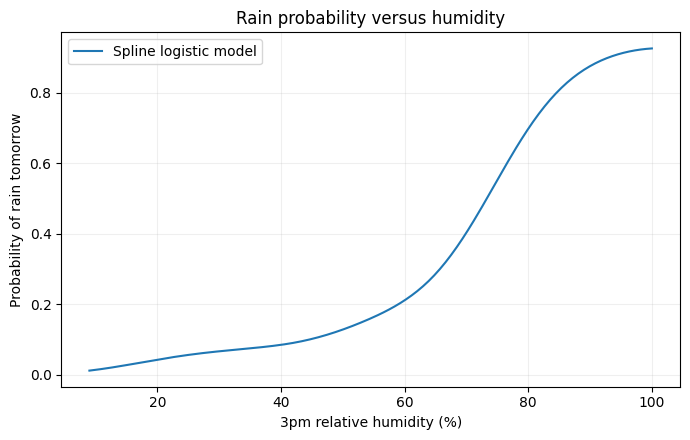


Seasonal smoothing results
CV-selected lambda: 0.005731169335512836
CV effective df: 13.28736591278691
CV error: 9.711848818497398

GCV-selected lambda: 0.002260491282079301
GCV effective df: 13.661641625261122
GCV error: 9.562088369260879


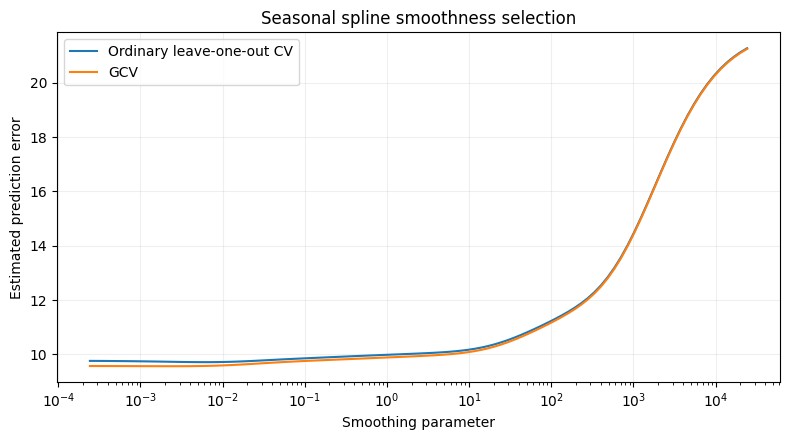

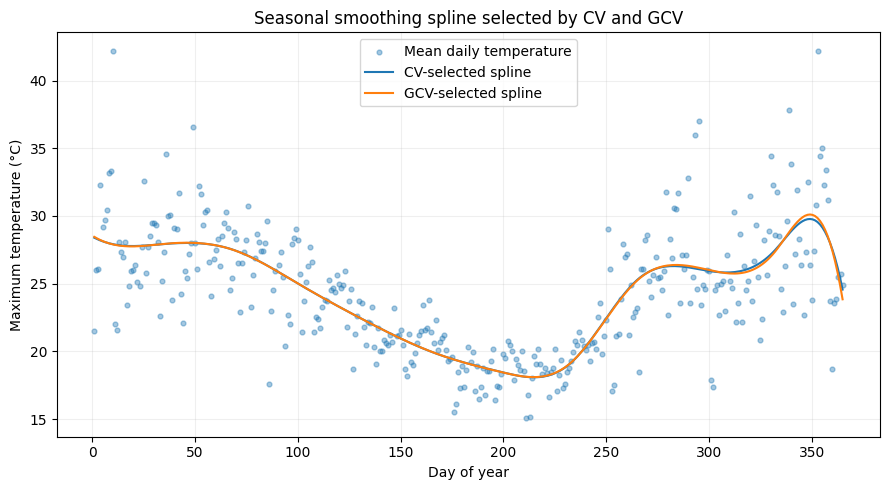

In [28]:
# Part 1: Logistic spline model for RainTomorrow
# I use smooth terms for humidity and pressure because their effects
# on rain probability may not be straight lines.

rg = rain.dropna(
    subset=["RainTomorrow", "Humidity3pm", "Pressure3pm"]
).copy()

rg["RainTomorrow"] = rg["RainTomorrow"].astype(int)

X = rg[["Humidity3pm", "Pressure3pm"]]
y = rg["RainTomorrow"]

# Create a separate spline basis for each predictor
humidity_spline = SplineTransformer(
    n_knots=5,
    degree=3,
    knots="quantile",
    include_bias=False,
    extrapolation="linear"
)

pressure_spline = SplineTransformer(
    n_knots=5,
    degree=3,
    knots="quantile",
    include_bias=False,
    extrapolation="linear"
)

H = humidity_spline.fit_transform(
    X[["Humidity3pm"]]
)

P = pressure_spline.fit_transform(
    X[["Pressure3pm"]]
)

# Combine the smooth terms
X_smooth = np.column_stack([H, P])

logistic_gam = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

logistic_gam.fit(X_smooth, y)

# 10-fold CV using the same spline transformations
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_errors = []

for train_idx, test_idx in cv.split(X):

    # Fit spline bases using training observations only
    h_train = SplineTransformer(
        n_knots=5,
        degree=3,
        knots="quantile",
        include_bias=False,
        extrapolation="linear"
    )

    p_train = SplineTransformer(
        n_knots=5,
        degree=3,
        knots="quantile",
        include_bias=False,
        extrapolation="linear"
    )

    train_h = h_train.fit_transform(
        X.iloc[train_idx][["Humidity3pm"]]
    )

    train_p = p_train.fit_transform(
        X.iloc[train_idx][["Pressure3pm"]]
    )

    test_h = h_train.transform(
        X.iloc[test_idx][["Humidity3pm"]]
    )

    test_p = p_train.transform(
        X.iloc[test_idx][["Pressure3pm"]]
    )

    train_basis = np.column_stack([train_h, train_p])
    test_basis = np.column_stack([test_h, test_p])

    fold_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )

    fold_model.fit(
        train_basis,
        y.iloc[train_idx]
    )

    fold_pred = fold_model.predict(test_basis)

    cv_errors.append(
        1 - accuracy_score(
            y.iloc[test_idx],
            fold_pred
        )
    )

print("Logistic spline training accuracy:",
      accuracy_score(y, logistic_gam.predict(X_smooth)))

print("Logistic spline 10-fold CV error:",
      round(np.mean(cv_errors), 4))

# Plot humidity effect while holding pressure at its median
humidity_grid = np.linspace(
    X["Humidity3pm"].min(),
    X["Humidity3pm"].max(),
    200
)

pressure_median = X["Pressure3pm"].median()

plot_data = pd.DataFrame({
    "Humidity3pm": humidity_grid,
    "Pressure3pm": pressure_median
})

plot_h = humidity_spline.transform(
    plot_data[["Humidity3pm"]]
)

plot_p = pressure_spline.transform(
    plot_data[["Pressure3pm"]]
)

plot_basis = np.column_stack([plot_h, plot_p])

probability = logistic_gam.predict_proba(
    plot_basis
)[:, 1]

plt.figure(figsize=(7, 4.5))

plt.plot(
    humidity_grid,
    probability,
    label="Spline logistic model"
)

plt.xlabel("3pm relative humidity (%)")
plt.ylabel("Probability of rain tomorrow")
plt.title("Rain probability versus humidity")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Part 2: Seasonal smoothness selection
# --------------------------------------------------

# I use Sydney's mean maximum temperature for each day of the year.
# Averaging across years gives one seasonal observation per day.

syd = weather[
    weather["Location"].str.contains("Sydney", case=False)
].dropna(
    subset=["MaxTemp", "doy"]
).copy()

seasonal = (
    syd.groupby("doy", as_index=False)["MaxTemp"]
    .mean()
    .sort_values("doy")
)

x = seasonal["doy"].to_numpy()
y = seasonal["MaxTemp"].to_numpy()

n = len(x)

# Build a cubic B-spline basis.
# The basis is fixed, so the smoothing parameter changes only
# the amount of penalisation.

spline_basis = SplineTransformer(
    n_knots=12,
    degree=3,
    knots="uniform",
    include_bias=True,
    extrapolation="linear"
)

B = spline_basis.fit_transform(
    x.reshape(-1, 1)
)

# Penalise changes in neighboring spline coefficients.
# This encourages a smoother seasonal curve.

n_basis = B.shape[1]

D = np.diff(
    np.eye(n_basis),
    n=2,
    axis=0
)

penalty = D.T @ D

# The unpenalised part of the model
BtB = B.T @ B

# Scale lambda relative to the design and penalty matrices
lambda_scale = (
    np.trace(BtB) /
    np.trace(penalty)
)

lambda_values = (
    lambda_scale *
    np.logspace(-4, 4, 100)
)

cv_errors = []
gcv_errors = []
effective_df = []
fits = []

# Evaluate every candidate smoothing parameter
for lam in lambda_values:

    # Penalised least-squares system
    A = BtB + lam * penalty

    # Calculate the smoother matrix
    A_inv_Bt = np.linalg.solve(
        A,
        B.T
    )

    S = B @ A_inv_Bt

    # Exact effective degrees of freedom for this fixed basis
    df_lambda = np.trace(S)

    effective_df.append(df_lambda)

    # Fitted seasonal temperatures
    fitted = S @ y

    residuals = y - fitted

    rss = np.sum(
        residuals ** 2
    )

    # Ordinary leave-one-out CV.
    # For a linear smoother, this uses the diagonal of S.
    h = np.diag(S)

    loo_residuals = (
        residuals /
        np.maximum(1 - h, 1e-8)
    )

    cv_error = np.mean(
        loo_residuals ** 2
    )

    cv_errors.append(cv_error)

    # Generalised cross-validation
    gcv_error = (
        rss / n
    ) / (
        1 - df_lambda / n
    ) ** 2

    gcv_errors.append(gcv_error)

    fits.append(fitted)


# Select the best smoothing parameter under each criterion
best_cv = int(np.argmin(cv_errors))
best_gcv = int(np.argmin(gcv_errors))

lambda_cv = lambda_values[best_cv]
lambda_gcv = lambda_values[best_gcv]

df_cv = effective_df[best_cv]
df_gcv = effective_df[best_gcv]

print("\nSeasonal smoothing results")

print("CV-selected lambda:", lambda_cv)
print("CV effective df:", df_cv)
print("CV error:", cv_errors[best_cv])

print("\nGCV-selected lambda:", lambda_gcv)
print("GCV effective df:", df_gcv)
print("GCV error:", gcv_errors[best_gcv])

# Plot CV and GCV against smoothing parameter
plt.figure(figsize=(8, 4.5))

plt.plot(
    lambda_values,
    cv_errors,
    label="Ordinary leave-one-out CV"
)

plt.plot(
    lambda_values,
    gcv_errors,
    label="GCV"
)

plt.xscale("log")

plt.xlabel("Smoothing parameter")
plt.ylabel("Estimated prediction error")
plt.title("Seasonal spline smoothness selection")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# Plot the selected seasonal curves
grid = np.linspace(
    x.min(),
    x.max(),
    300
)

grid_basis = spline_basis.transform(
    grid.reshape(-1, 1)
)

# Refit using the selected smoothing parameters
A_cv = BtB + lambda_cv * penalty

coef_cv = np.linalg.solve(
    A_cv,
    B.T @ y
)

A_gcv = BtB + lambda_gcv * penalty

coef_gcv = np.linalg.solve(
    A_gcv,
    B.T @ y
)

curve_cv = grid_basis @ coef_cv
curve_gcv = grid_basis @ coef_gcv

plt.figure(figsize=(9, 5))

plt.scatter(
    x,
    y,
    s=12,
    alpha=0.4,
    label="Mean daily temperature"
)

plt.plot(
    grid,
    curve_cv,
    label="CV-selected spline"
)

plt.plot(
    grid,
    curve_gcv,
    label="GCV-selected spline"
)

plt.xlabel("Day of year")
plt.ylabel("Maximum temperature (°C)")
plt.title("Seasonal smoothing spline selected by CV and GCV")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()